# 01. Lattice and normal-state Hamiltonian

Start with the site numbering and hopping in your code, then compare it with the Hamiltonian in thesis §4.4. The two constructions are kept separate.

**Read this notebook from top to bottom.** Each section explains one calculation before showing its code. All functions needed to run it are visible below; no earlier notebook is required.

**Source labels.** **Thesis** identifies the stated model in Aditya Banerjee's [2023 MSc thesis](https://drive.google.com/file/d/1d9WheYwEY23cPAlLxxVOUfQDr9jLdqb9/view). **Source translation** identifies the active Mathematica calculation at commit `d88d12c`. **Extension / algebra** identifies new Python implementation or explicit derivations. Numerical output is evidence only for the displayed parameters. No speculative physical identification is assumed.

**Units and conventions.** Choose one energy unit $E_0$ and lattice spacing $a$. Displayed energies mean $E/E_0$, coordinates mean $x/a$, and $k_x,k_y$ mean momentum times $a$. Thus $m,\lambda,\mu,\Delta,V,k_BT$ all have energy units before rescaling. Eigenvectors have norm one and dimensionless components. This is a nonrelativistic lattice calculation; no spacetime metric signature is used. Boundary conditions and the spin/Nambu basis are stated where each matrix is built.

**Code provenance.** The original files are [BdG topological.nb](https://github.com/adicos0/BdG-code-for-Topological-superconductor-with-vortex-/blob/d88d12cded1a954d53c2d36d515525c8100ded1c/BdG%20topological.nb) and [added vortex.nb](https://github.com/adicos0/BdG-code-for-Topological-superconductor-with-vortex-/blob/d88d12cded1a954d53c2d36d515525c8100ded1c/added%20vortex.nb). See [SOURCE_MAP.md](../SOURCE_MAP.md) for exact cells, differences and references. Python functions are also collected in `python/bdg_models.py` for testing; the definitions here are identical.

## 1. Imports

In [1]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh
from scipy.special import expit
plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})

Matplotlib is building the font cache; this may take a moment.


## 2. Number the sites — source translation

The source loops over $x$ first and $y$ second. With one-based coordinates it uses
$$i=(x-1)N_y+y.$$
Python uses zero-based coordinates, so
$$i=xN_y+y,\qquad N=N_xN_y.$$
Here $N_x,N_y$ count sites along each direction and $N$ is the total number of sites. The source uses $20\times20$ with periodic boundaries. We use $6\times6$ for a quick demonstration. This changes the finite-size spectrum; it is not a reproduction of a thesis figure.

In [2]:
def coordinates(nx, ny):
    """Zero-based version of the source's x-outer, y-inner site order."""
    return np.array([(x, y) for x in range(nx) for y in range(ny)])

Number of sites: 36
First six (x,y) coordinates: [[0, 0], [0, 1], [0, 2], [0, 3], [0, 4], [0, 5]]


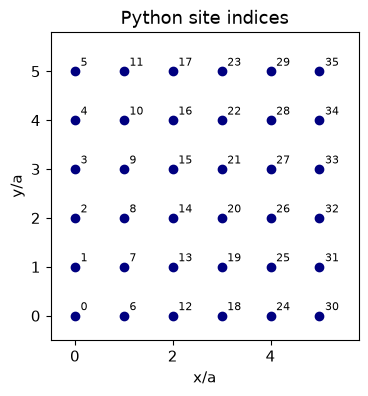

In [3]:
nx = ny = 6
xy = coordinates(nx, ny)
n = nx*ny
print("Number of sites:", n)
print("First six (x,y) coordinates:", xy[:6].tolist())
fig, ax = plt.subplots()
ax.scatter(xy[:, 0], xy[:, 1], color="navy")
for i, (x, y) in enumerate(xy):
    ax.annotate(str(i), (x, y), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set(xlabel="x/a", ylabel="y/a", title="Python site indices", aspect="equal",
       xlim=(-0.5, nx-0.2), ylim=(-0.5, ny-0.2))
plt.show()

## 3. Build the hopping used by the active source

**Source translation:** first `Code` cell, followed by the active iteration cell. Its scalar hopping values are $3m/2$ onsite, $-m$ for four axial neighbours and $m/4$ for four diagonal neighbours. Its spin-mixing amplitude is $\lambda(1-i)$ for every axial direction.

Let $H_1$ denote the scalar hopping matrix and $S$ the spin-mixing matrix. The active electron block is
$$h_{\rm src}=\begin{pmatrix}H_1+\mu I&S\\S^*&H_1+\mu I\end{pmatrix}.$$
$S$ is symmetric for these dictionaries, so $S^*=S^\dagger$. The separately defined `Hop1x` function has a minus sign on the lower $H_1$, but **the active loop does not use that function**. We preserve the active loop.

**Algebra check:** periodic Fourier transformation of these dictionaries gives
$$H_1(k)=\frac{3m}{2}-2m(\cos k_x+\cos k_y)+m\cos k_x\cos k_y,$$
$$S(k)=2\lambda(1-i)(\cos k_x+\cos k_y).$$
Each pair of opposite axial bonds supplies $e^{ik}+e^{-ik}=2\cos k$. The four diagonal bonds supply
$(e^{ik_x}+e^{-ik_x})(e^{ik_y}+e^{-ik_y})=4\cos k_x\cos k_y$.
All terms have energy units. These expressions differ from thesis Eq. (4.8).

In [4]:
def legacy_blocks(nx, ny, m=0.5, lam=1.0):
    """Translate first Code cell: periodic dictionary hopping, not thesis Eq. 4.9.

    Require >=3 sites per direction so nearest-neighbour images are distinct.
    The source selects the first numeric periodic image, rather than summing
    duplicate images. These coincide for the supported sizes.
    """
    if min(nx, ny) < 3:
        raise ValueError('Legacy translation requires nx, ny >= 3.')
    xy = coordinates(nx, ny)
    n = nx * ny
    hopping = {(0, 0): 1.5*m}
    for dx, dy in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
        hopping[dx, dy] = -m
    for dx in [-1, 1]:
        for dy in [-1, 1]:
            hopping[dx, dy] = m/4
    mixing = {d: lam*(1-1j) for d in [(1, 0), (-1, 0), (0, 1), (0, -1)]}

    def from_dictionary(entries):
        matrix = np.zeros((n, n), complex)
        for i, (x, y) in enumerate(xy):
            for (dx, dy), value in entries.items():
                j = ((x-dx) % nx)*ny + (y-dy) % ny
                matrix[i, j] = value
        return matrix.T  # source: tij[i][j] = tijmn[[j,i]]

    return from_dictionary(hopping), from_dictionary(mixing)

In [5]:
h1, soc = legacy_blocks(nx, ny)
mu = 0.0
h_source = np.block([[h1 + mu*np.eye(n), soc],
                     [soc.conj(), h1 + mu*np.eye(n)]])
print("Electron matrix shape:", h_source.shape)
print("Hermiticity residual:", np.max(abs(h_source-h_source.conj().T)))

Electron matrix shape: (72, 72)
Hermiticity residual: 0.0


## 4. Build the thesis Hamiltonian — explicitly separate extension

**Thesis:** §4.4, Eqs. (4.8)–(4.9), pp. 45–46:
$$h(k)=\lambda(\sigma_x\sin k_x+\sigma_y\sin k_y)+M_k\sigma_z-\mu I,$$
$$M_k=m\left[(2-\cos k_x-\cos k_y)-\frac14(2-\cos2k_x-\cos2k_y)\right].$$
The $\sigma$ matrices act on physical spin, $\lambda$ controls spin-dependent hopping, $m$ controls the lattice mass and $\mu$ is the chemical potential in this equation's sign convention.

**Algebra, with Fourier convention** $c_r=N^{-1/2}\sum_k e^{-ik\cdot r}c_k$:

1. Collect the constants: $2m-m/2=3m/2$.
2. A nearest axial hopping $-m\sigma_z/2$ plus its adjoint produces $-m\sigma_z\cos k_\alpha$.
3. A distance-two axial hopping $m\sigma_z/8$ plus its adjoint produces $(m/4)\sigma_z\cos2k_\alpha$.
4. A spin hopping $i\lambda\sigma_\alpha/2$ plus its adjoint gives
$$\frac{i\lambda}{2}\sigma_\alpha(e^{-ik_\alpha}-e^{ik_\alpha})=\lambda\sigma_\alpha\sin k_\alpha.$$
Thus each positive nearest bond has $-m\sigma_z/2+i\lambda\sigma_\alpha/2$ and each positive distance-two bond has $m\sigma_z/8$. These are **axial distance-two**, not diagonal, bonds.

**Limiting cases:** at $k=0$, $M_k=0$. Using $\cos k=1-k^2/2+k^4/24+O(k^6)$,
$$1-\cos k=k^2/2-k^4/24+O(k^6),$$
$$\tfrac14(1-\cos2k)=k^2/2-k^4/6+O(k^6),$$
so subtraction gives $k^4/8+O(k^6)$ and $M_k=m(k_x^4+k_y^4)/8+O(k^6)$.

**Source correction:** this spin mass breaks physical time-reversal symmetry, contrary to the sentence after thesis Eq. (4.8). Under spin time reversal, $\sigma_z\to-\sigma_z$ while $M_{-k}=M_k$. See the model discussion in [Pathak, Plugge & Franz, §2.1](https://arxiv.org/html/2012.10588v2).

In [6]:
def thesis_normal(nx, ny, m=0.5, lam=1.0, mu=0.0, periodic=False):
    """Extension from thesis Eqs. 4.8-4.9, not the active source hopping.

    Fourier convention c_r = sum_k exp(-i k.r)c_k / sqrt(N).
    Build site-major 2x2 blocks, then permute to spin-major order.
    """
    identity = np.eye(2)
    sx = np.array([[0, 1], [1, 0]], complex)
    sy = np.array([[0, -1j], [1j, 0]], complex)
    sz = np.diag([1., -1.])
    n = nx*ny
    h = np.kron(np.eye(n), 1.5*m*sz-mu*identity).astype(complex)
    for i, (x, y) in enumerate(coordinates(nx, ny)):
        for dx, dy, spin in [(1, 0, sx), (0, 1, sy)]:
            for distance, hop in [(1, -m/2*sz + 0.5j*lam*spin),
                                  (2, m/8*sz)]:
                xx, yy = x+distance*dx, y+distance*dy
                if not periodic and not (0 <= xx < nx and 0 <= yy < ny):
                    continue
                j = (xx % nx)*ny + (yy % ny)
                h[2*i:2*i+2, 2*j:2*j+2] += hop
                h[2*j:2*j+2, 2*i:2*i+2] += hop.conj().T
    order = np.r_[np.arange(0, 2*n, 2), np.arange(1, 2*n, 2)]
    return h[np.ix_(order, order)]

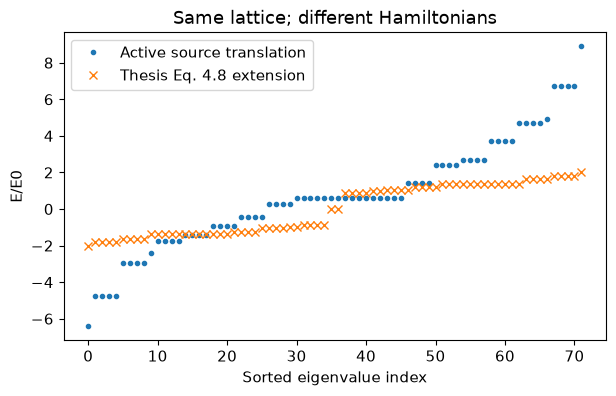

Thesis k=0 residual at mu=0: 8.326672684688674e-17


In [7]:
h_thesis = thesis_normal(nx, ny, periodic=True)
e_source = eigh(h_source, eigvals_only=True)
e_thesis = eigh(h_thesis, eigvals_only=True)
fig, ax = plt.subplots()
ax.plot(e_source, ".", label="Active source translation")
ax.plot(e_thesis, "x", label="Thesis Eq. 4.8 extension")
ax.set(xlabel="Sorted eigenvalue index", ylabel="E/E0", title="Same lattice; different Hamiltonians")
ax.legend()
plt.show()
# Uniform k=0 spinors test the thesis limit h(0) = -mu I.
constant_up = np.r_[np.ones(n), np.zeros(n)] / np.sqrt(n)
print("Thesis k=0 residual at mu=0:", np.linalg.norm(h_thesis @ constant_up))

## 5. What this establishes

**Computed fact:** the two implementations produce different normal-state spectra. The matrix comparison is a source audit, not a phase diagram. **Model assumption:** the thesis-based implementation uses its stated spin Hamiltonian. Later vortex examples explicitly use this extension. The self-consistency notebook instead translates the original active code.